In [ ]:
# Import Modul
import pandas as pd
import re
import seaborn as sns
import matplotlib.pyplot as plt


In [ ]:
# Data Collection
df = pd.read_csv('ulasan_playstore.csv')
df.head(20)

,content,score
0,aku dapat jodoh di aplikasi ini Terima kasih omi,5
1,terlalu mahal,1
2,sangat bagus,1
3,aplikasi bagus untuk saya,5
4,baiak,5
5,mantap,5
6,bgus,5
7,mantap. aplikasi ini,5
8,Windaratnawijaya ❤️❤️🫰❤️,5
9,"aplikasi membntu mencari teman, okk",5


**Preprocessing**

In [ ]:
# Data Cleaning

# Menghapus data yang duplicated
df = df.drop_duplicates(subset='content')


def clean_content(text):
    # Pastikan input berupa string
    if not isinstance(text, str):
        return ""
    # Case folding
    text = text.lower()
    # Hapus URL
    text = re.sub(r'http\S+|www\S+', '', text)
    # Hapus mention (@username)
    text = re.sub(r'@\w+', '', text)
    # Hapus hashtag (#topik)
    text = re.sub(r'#\w+', '', text)
    # Hapus emoji
    text = re.sub(
        "["
        "\U0001F600-\U0001F64F"
        "\U0001F300-\U0001F5FF"
        "\U0001F680-\U0001F6FF"
        "\U0001F1E0-\U0001F1FF"
        "]+",
        "",
        text
    )

    # Hapus angka & tanda baca (sisakan huruf)
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Hapus spasi berlebih
    text = re.sub(r'\s+', ' ', text).strip()

    return text




df['content_Clean'] = df['content'].apply(clean_content)


# pd.set_option('display.max_colwidth', None)
# pd.set_option('display.max_rows', None)
# pd.set_option('display.max_columns', None)

# df




In [ ]:
# Normalisasi Teks
def normalisasi_teks(text):
    # Kamus normalisasi
    norm = {
        # Negasi & singkatan umum
        'nggak': 'tidak', 'gak': 'tidak', 'ga': 'tidak', 'tdk': 'tidak',
        'blm': 'belum', 'udah': 'sudah', 'trs': 'terus',
        # Kata hubung & umum
        'yg': 'yang', 'dgn': 'dengan', 'klo': 'kalau', 'krn': 'karena',
        # Emosi / penilaian (sentimen)
        'bgt': 'banget', 'mantul': 'bagus', 'bgus': 'bagus',
        'jelekkk': 'jelek', 'parahh': 'parah', 'kecewaaa': 'kecewa',
        # Istilah aplikasi kencan
        'match': 'cocok', 'bguss': 'bagus', 'good': 'bagus', 'ngechat': 'chat',
        'premium': 'berbayar', 'vip': 'berbayar', 'mahalnya': 'mahal',
        # Kesalahan ketik umum
        'membntu': 'membantu', 'baiak': 'baik', 'ndk': 'tidak', 'ngak': 'tidak',
        # Penilaian layanan
        'lemot': 'lambat', 'error': 'bermasalah', 'fake': 'palsu', 'tipu': 'penipuan'
    }

    # Normalisasi kata per kata
    words = text.split()
    words = [norm.get(w, w) for w in words]
    return " ".join(words)

# Terapkan normalisasi ke DataFrame
df['content_Clean'] = df['content_Clean'].apply(normalisasi_teks)

# Tampilkan seluruh DataFrame tanpa terpotong
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

df


,content,score,content_Clean
0,aku dapat jodoh di aplikasi ini Terima kasih omi,5,aku dapat jodoh di aplikasi ini terima kasih omi
1,terlalu mahal,1,terlalu mahal
2,sangat bagus,1,sangat bagus
3,aplikasi bagus untuk saya,5,aplikasi bagus untuk saya
4,baiak,5,baik
5,mantap,5,mantap
6,bgus,5,bagus
7,mantap. aplikasi ini,5,mantap aplikasi ini
8,Windaratnawijaya ❤️❤️🫰❤️,5,windaratnawijaya
9,"aplikasi membntu mencari teman, okk",5,aplikasi membantu mencari teman okk


In [ ]:
# StopWord
!pip install Sastrawi #Library

from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

factory = StopWordRemoverFactory()
stopwords = set(factory.get_stop_words())

# Kata negasi penting untuk sentimen → JANGAN dihapus
negasi = {'tidak', 'bukan', 'jangan', 'kurang'}
stopwords = stopwords - negasi

def stopword_removal(text):
    words = text.split()
    words = [w for w in words if w not in stopwords]
    return " ".join(words)

df['content_Clean'] = df['content_Clean'].apply(stopword_removal)
# pd.set_option('display.max_colwidth', None)
# pd.set_option('display.max_rows', None)
# pd.set_option('display.max_columns', None)

df

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 5.1 MB/s eta 0:00:00


,content,score,content_Clean
0,aku dapat jodoh di aplikasi ini Terima kasih omi,5,aku jodoh aplikasi terima kasih omi
1,terlalu mahal,1,terlalu mahal
2,sangat bagus,1,sangat bagus
3,aplikasi bagus untuk saya,5,aplikasi bagus
4,baiak,5,baik
...,...,...,...
992,cakep,4,cakep
993,ngak usah di download dari pada dana kalian ke...,1,ngak usah download dana kalian ketarik omi bra...
996,aplikasi yg sangat bagus kita dapat temen baru,5,aplikasi sangat bagus temen baru
997,makasih ya omi berkat apk ini aku bisa dapet c...,5,makasih omi berkat apk aku dapet calon suami


In [ ]:
# Tokenize
def tokenize(text):
    if not isinstance(text, str):
        return []
    return text.split()
df['Token'] = df['content_Clean'].apply(tokenize)
df[['content_Clean', 'Token']].head()
# pd.set_option('display.max_colwidth', None)
# pd.set_option('display.max_rows', None)
# pd.set_option('display.max_columns', None)
# df


,content_Clean,Token
0,aku jodoh aplikasi terima kasih omi,"[aku, jodoh, aplikasi, terima, kasih, omi]"
1,terlalu mahal,"[terlalu, mahal]"
2,sangat bagus,"[sangat, bagus]"
3,aplikasi bagus,"[aplikasi, bagus]"
4,baik,[baik]


In [ ]:
# Stemming
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

factory = StemmerFactory()
stemmer = factory.create_stemmer()

def stemming(text):
    if not isinstance(text, str):
        return ""
    return stemmer.stem(text)

df['content_Clean'] = df['content_Clean'].apply(stemming)
df[['content', 'content_Clean']].head(20)



,content,score,content_Clean
0,aku dapat jodoh di aplikasi ini Terima kasih omi,5,aku dapat jodoh di aplikasi ini terima kasih omi
1,terlalu mahal,1,terlalu mahal
2,sangat bagus,1,sangat bagus
3,aplikasi bagus untuk saya,5,aplikasi bagus untuk saya
4,baiak,5,baik
5,mantap,5,mantap
6,bgus,5,bagus
7,mantap. aplikasi ini,5,mantap aplikasi ini
8,Windaratnawijaya ❤️❤️🫰❤️,5,windaratnawijaya
9,"aplikasi membntu mencari teman, okk",5,aplikasi bantu cari teman okk


In [ ]:
# Labelling
kata_positif = {
    'bagus','baik','mantap','keren','hebat','tepat','puas',
    'cocok','cocokan','nyambung','match','jodoh','ketemu',
    'terbaik','senang','happy','suka','puasin',
    'nyaman','aman','percaya','real','asli','serius',
    'lancar','cepat','mudah','responsif','aktif',
    'fitur','lengkap','menarik','userfriendly',
    'akurat','relevan','stabil',
    'berguna','bermanfaat','worth','worthit',
    'recommended','membantu','sukses','oke','ok',
    'bantu',''
}


kata_negatif = {
    'palsu','fake','scam','penipu','tipu','bohong',
    'akunpalsu','bot','penipuan',
    'error','bug','lemot','lag','crash','loading',
    'gagal','rusak','forceclose',
    'mahal','bayar','berbayar','premium',
    'percuma','ripoff',
    'kecewa','parah','buruk','jelek','zonk',
    'sepi','ghosting','toxic','spam','iklan',
    'tidakaman','curiga','data','bocor','privasi','nyesal'
    'hancur'
}



def label_sentimen(text):
    if not isinstance(text, str):
        return 'netral'

    pos = 0
    neg = 0

    for word in text.split():
        if word in kata_positif:
            pos += 1
        elif word in kata_negatif:
            neg += 1

    if pos > neg:
        return 'positif'
    elif neg > pos:
        return 'negatif'
    else:
        return 'netral'

df['label'] = df['content_Clean'].apply(label_sentimen)
df[['content_Clean', 'label']].head()

jumlah_sentimen = df['label'].value_counts()

positif = jumlah_sentimen.get('positif', 0)
negatif = jumlah_sentimen.get('negatif', 0)
netral  = jumlah_sentimen.get('netral', 0)

total = positif + negatif + netral

print("Jumlah Positif :", positif)
print("Jumlah Negatif :", negatif)
print("Jumlah Netral  :", netral)
print("Total Komentar :", total)



Jumlah Positif : 286
Jumlah Negatif : 98
Jumlah Netral  : 346
Total Komentar : 730


In [ ]:
df['label'] = df['content_Clean'].apply(label_sentimen)
df.head(20)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

df

,content,score,content_Clean,label
0,aku dapat jodoh di aplikasi ini Terima kasih omi,5,aku dapat jodoh di aplikasi ini terima kasih omi,positif
1,terlalu mahal,1,terlalu mahal,negatif
2,sangat bagus,1,sangat bagus,positif
3,aplikasi bagus untuk saya,5,aplikasi bagus untuk saya,positif
4,baiak,5,baik,positif
5,mantap,5,mantap,positif
6,bgus,5,bagus,positif
7,mantap. aplikasi ini,5,mantap aplikasi ini,positif
8,Windaratnawijaya ❤️❤️🫰❤️,5,windaratnawijaya,netral
9,"aplikasi membntu mencari teman, okk",5,aplikasi bantu cari teman okk,netral


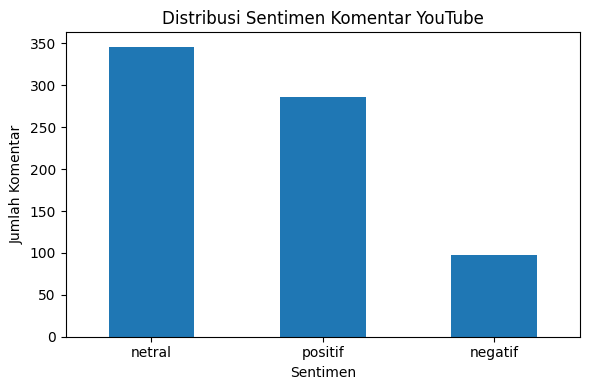

In [ ]:
# Bar Chart
# Hitung jumlah sentimen
sentimen_counts = df['label'].value_counts()

# Plot bar chart
plt.figure(figsize=(6,4))
sentimen_counts.plot(kind='bar')
plt.title('Distribusi Sentimen Komentar YouTube')
plt.xlabel('Sentimen')
plt.ylabel('Jumlah Komentar')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# # Pie Chart
# plt.figure(figsize=(6,6))
# sentimen_counts.plot(
#     kind='pie',
#     autopct='%1.1f%%',
#     startangle=90
# )
# plt.title('Persentase Sentimen Komentar')
# plt.ylabel('')
# plt.tight_layout()
# plt.show()


In [ ]:
!pip install wordcloud



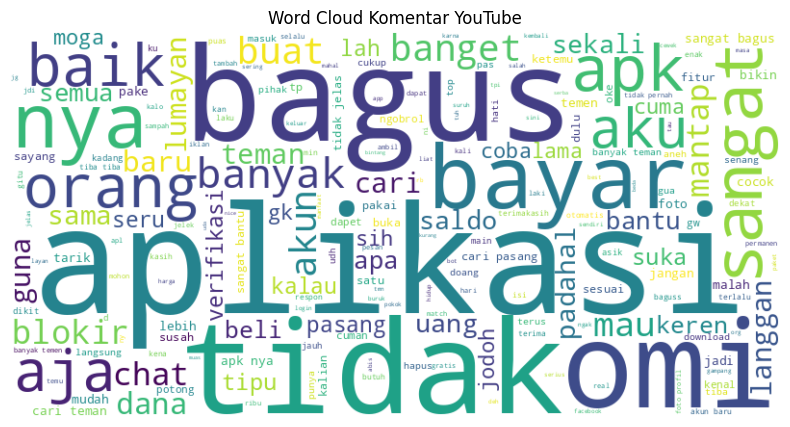

In [ ]:
# World Cloud
from wordcloud import WordCloud
import matplotlib.pyplot as plt

text = " ".join(df['content_Clean'].dropna())

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white'
).generate(text)

plt.figure(figsize=(10,5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud Komentar YouTube')
plt.show()


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Target dan Fitur
X = df['content_Clean']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1,2)
)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)

nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

y_pred = nb_model.predict(X_test_tfidf)



In [ ]:
# Menguji Akurasi Model
akurasi = accuracy_score(y_test, y_pred)
print("Akurasi Model:", akurasi)


Akurasi Model: 0.821917808219178


In [ ]:
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

     negatif       1.00      0.10      0.18        20
      netral       0.79      0.93      0.85        69
     positif       0.86      0.95      0.90        57

    accuracy                           0.82       146
   macro avg       0.88      0.66      0.65       146
weighted avg       0.85      0.82      0.78       146



In [ ]:
cm = confusion_matrix(y_test, y_pred)
cm


array([[ 2, 14,  4],
       [ 0, 64,  5],
       [ 0,  3, 54]])

In [ ]:
X_all_tfidf = tfidf.transform(df['content_Clean'])
df['Prediksi_NB'] = nb_model.predict(X_all_tfidf)


In [ ]:
df[['content','content_Clean', 'label', 'Prediksi_NB']].head(10)



,content,content_Clean,label,Prediksi_NB
0,aku dapat jodoh di aplikasi ini Terima kasih omi,aku jodoh aplikasi terima kasih omi,positif,positif
1,terlalu mahal,terlalu mahal,negatif,netral
2,sangat bagus,sangat bagus,positif,positif
3,aplikasi bagus untuk saya,aplikasi bagus,positif,positif
4,baiak,baik,positif,positif
5,mantap,mantap,positif,positif
6,bgus,bagus,positif,positif
7,mantap. aplikasi ini,mantap aplikasi,positif,positif
8,Windaratnawijaya ❤️❤️🫰❤️,windaratnawijaya,netral,netral
9,"aplikasi membntu mencari teman, okk",aplikasi bantu cari teman okk,netral,netral


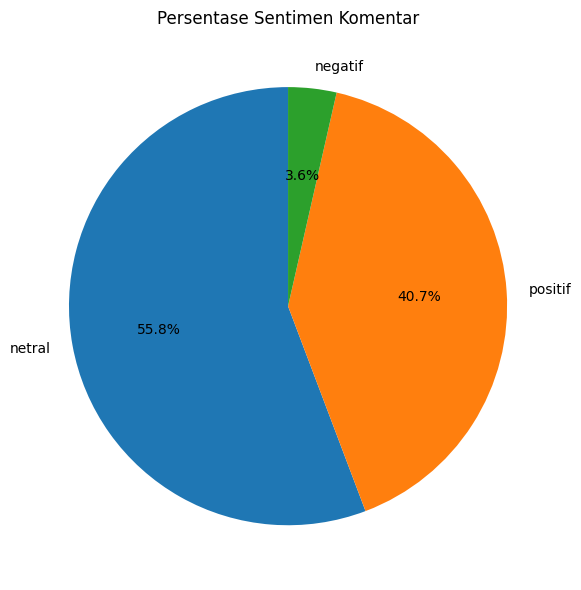

In [ ]:
# Pie Chart
sentimen_counts = df['Prediksi_NB'].value_counts()
plt.figure(figsize=(6,6))
sentimen_counts.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Persentase Sentimen Komentar')
plt.ylabel('')
plt.tight_layout()
plt.show()

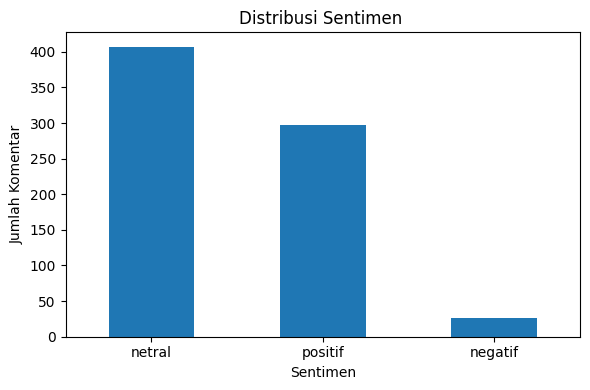

In [ ]:
# Bar Chart Hasil dari analisis NB
# Hitung jumlah sentimen
sentimen_counts = df['Prediksi_NB'].value_counts()

# Plot bar chart
plt.figure(figsize=(6,4))
sentimen_counts.plot(kind='bar')
plt.title('Distribusi Sentimen ')
plt.xlabel('Sentimen')
plt.ylabel('Jumlah Komentar')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# Testing
import re
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

# Stemmer
stemmer = StemmerFactory().create_stemmer()

# Stopword
factory = StopWordRemoverFactory()
stopwords = set(factory.get_stop_words()) - {'tidak','bukan','jangan','kurang'}

# Cleaning
def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'#\w+', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Normalisasi
def normalisasi_teks(text):
    norm = {
        'nggak': 'tidak',
        'gak': 'tidak',
        'ga': 'tidak',
        'tdk': 'tidak',
        'yg': 'yang',
        'bgt': 'banget',
        'dgn': 'dengan',
        'klo':'kalau',
        'mantul' : 'bagus',
        'membntu':'membantu',
        'bgus':'bagus'
    }
    return " ".join([norm.get(w, w) for w in text.split()])

# Stopword removal
def stopword_removal(text):
    return " ".join([w for w in text.split() if w not in stopwords])

# Stemming
def stemming(text):
    return stemmer.stem(text)

# Pipeline preprocessing
def preprocessing_testing(text):
    text = clean_text(text)
    text = normalisasi_teks(text)
    text = stopword_removal(text)
    text = stemming(text)
    return text



In [ ]:
# Input komentar dari user
komentar_user = input("Masukkan komentar YouTube: ")

# Preprocessing
komentar_clean = preprocessing_testing(komentar_user)

# TF-IDF transform (JANGAN fit ulang)
komentar_tfidf = tfidf.transform([komentar_clean])

# Prediksi Naive Bayes
hasil = nb_model.predict(komentar_tfidf)

print("\nKomentar Asli :", komentar_user)
print("Komentar Clean:", komentar_clean)
print("Hasil Sentimen:", hasil[0])


Masukkan komentar YouTube: bagus mahal 

Komentar Asli : bagus mahal 
Komentar Clean: bagus mahal
Hasil Sentimen: positif
